# Uniform Cost Search: Self-Driving Trailer Agent
**Practical Exercise 3 (Part 2)**

**Problem:** a trailer must travel from **Nairobi** to **Kisumu** across the highway network. Using the directed graph and path costs (km) from Part 1, find the **cheapest route** with **Uniform Cost Search (UCS)**.

**Search problem formulation**
| Component | Definition |
|---|---|
| Initial state | Nairobi |
| Actions | Drive along a highway leaving the current town |
| Transition model | Driving edge (A → B) puts the trailer in town B |
| Goal test | Current town is Kisumu |
| Path cost | Sum of road distances (km) along the route |

## 1. Build the directed graph
Each edge `(A, B, km)` is a highway segment the trailer can drive from A towards B, with its distance as the step cost.

In [1]:
EDGES = [
    ("Nairobi",  "Thika",    45),
    ("Thika",    "Nyeri",    113),
    ("Nairobi",  "Naivasha", 90),
    ("Naivasha", "Nakuru",   70),
    ("Nakuru",   "Kericho",  106),
    ("Kericho",  "Kisumu",   85),
    ("Nakuru",   "Eldoret",  156),
    ("Eldoret",  "Kisumu",   117),
]

graph = {}
for a, b, km in EDGES:
    graph.setdefault(a, []).append((b, km))
    graph.setdefault(b, [])          # make sure every town appears as a key

for town, roads in graph.items():
    print(f"{town:<9} -> {roads}")

Nairobi   -> [('Thika', 45), ('Naivasha', 90)]
Thika     -> [('Nyeri', 113)]
Nyeri     -> []
Naivasha  -> [('Nakuru', 70)]
Nakuru    -> [('Kericho', 106), ('Eldoret', 156)]
Kericho   -> [('Kisumu', 85)]
Kisumu    -> []
Eldoret   -> [('Kisumu', 117)]


## 2. Visualise the highway network

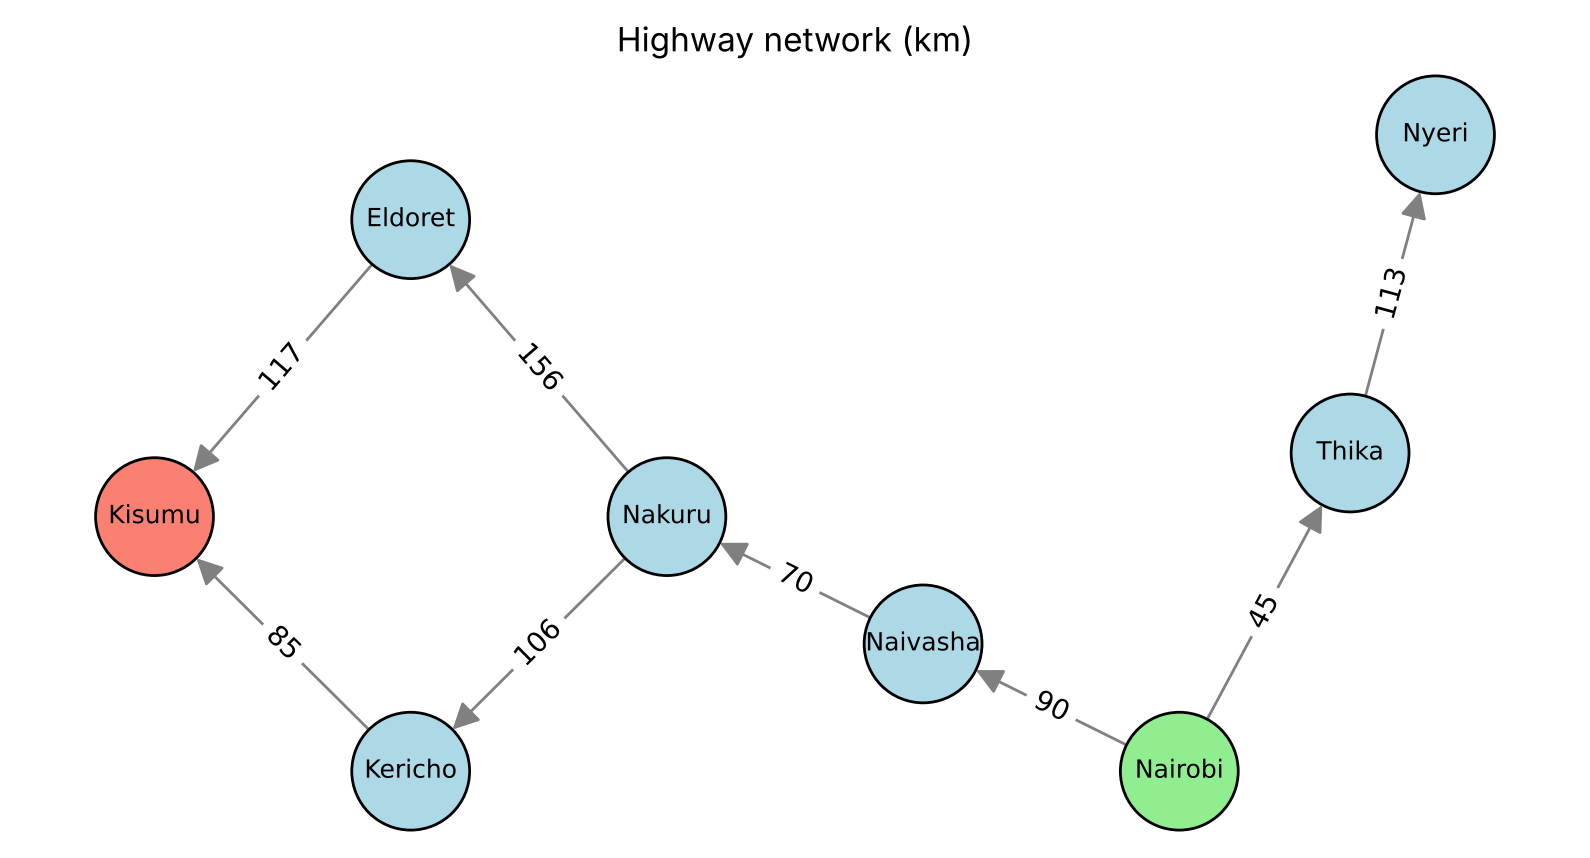

In [2]:
import networkx as nx
import matplotlib.pyplot as plt

G = nx.DiGraph()
G.add_weighted_edges_from(EDGES)

pos = {"Nairobi": (6, 0), "Thika": (7, 1.5), "Nyeri": (7.5, 3),
       "Naivasha": (4.5, 0.6), "Nakuru": (3, 1.2), "Kericho": (1.5, 0),
       "Eldoret": (1.5, 2.6), "Kisumu": (0, 1.2)}

def draw(highlight=None, title="Highway network (km)"):
    plt.figure(figsize=(10, 5))
    colours = ["lightgreen" if n == "Nairobi" else "salmon" if n == "Kisumu"
               else "lightblue" for n in G.nodes]
    nx.draw_networkx_nodes(G, pos, node_color=colours, node_size=1800, edgecolors="black")
    nx.draw_networkx_labels(G, pos, font_size=9)
    nx.draw_networkx_edges(G, pos, arrows=True, arrowsize=20, node_size=1800, edge_color="grey")
    if highlight:
        path_edges = list(zip(highlight, highlight[1:]))
        nx.draw_networkx_edges(G, pos, edgelist=path_edges, arrows=True, arrowsize=22,
                               node_size=1800, edge_color="red", width=3)
    nx.draw_networkx_edge_labels(G, pos, edge_labels=nx.get_edge_attributes(G, "weight"))
    plt.title(title)
    plt.axis("off")
    plt.show()

draw()

## 3. Uniform Cost Search
- **Frontier**: a priority queue of `(path cost g(n), town, path)`. `heapq` always pops the node with the lowest cost.
- **Explored set**: towns that have already been expanded are not expanded again.
- **Frontier update**: if a town is already on the frontier with a higher cost, the cheaper path replaces it. A more expensive duplicate is ignored.
- **Goal test** is applied when a node is **popped (expanded)**, not when it is generated. This is what makes UCS optimal.

In [3]:
import heapq

def uniform_cost_search(graph, start, goal):
    frontier = [(0, start, [start])]
    best_cost = {start: 0}            # cheapest known cost of each town on the frontier
    explored = set()
    step = 0

    print(f"UNIFORM COST SEARCH: {start} -> {goal}\n")
    print(f"{'Step':<5}{'Expand':<10}{'g(n)':<6}{'Frontier (sorted by cost)':<45}Explored")
    print("-" * 100)

    while frontier:
        cost, town, path = heapq.heappop(frontier)
        if town in explored or cost > best_cost.get(town, float("inf")):
            continue                  # outdated entry: a cheaper path was found

        step += 1
        if town == goal:
            print(f"{step:<5}{town:<10}{cost:<6}GOAL TEST PASSED - optimal path found")
            return path, cost

        explored.add(town)
        for nxt, km in graph[town]:
            new_cost = cost + km
            if nxt not in explored and new_cost < best_cost.get(nxt, float("inf")):
                best_cost[nxt] = new_cost
                heapq.heappush(frontier, (new_cost, nxt, path + [nxt]))

        live = sorted((c, t) for c, t, _ in frontier
                      if t not in explored and c == best_cost[t])
        f_txt = ", ".join(f"{t}({c})" for c, t in live) or "(empty)"
        print(f"{step:<5}{town:<10}{cost:<6}{f_txt:<45}{sorted(explored)}")

    return None, float("inf")

## 4. Run the search and present the optimal path

In [4]:
path, total = uniform_cost_search(graph, "Nairobi", "Kisumu")

print("\n" + "=" * 100)
if path:
    legs = [dict(graph[a])[b] for a, b in zip(path, path[1:])]
    print("OPTIMAL PATH :", " -> ".join(path))
    print("LEG COSTS    :", " + ".join(map(str, legs)), "=", sum(legs), "km")
    print("TOTAL COST   :", total, "km")
else:
    print("No path from Nairobi to Kisumu.")

UNIFORM COST SEARCH: Nairobi -> Kisumu

Step Expand    g(n)  Frontier (sorted by cost)                    Explored
----------------------------------------------------------------------------------------------------
1    Nairobi   0     Thika(45), Naivasha(90)                      ['Nairobi']
2    Thika     45    Naivasha(90), Nyeri(158)                     ['Nairobi', 'Thika']
3    Naivasha  90    Nyeri(158), Nakuru(160)                      ['Nairobi', 'Naivasha', 'Thika']
4    Nyeri     158   Nakuru(160)                                  ['Nairobi', 'Naivasha', 'Nyeri', 'Thika']
5    Nakuru    160   Kericho(266), Eldoret(316)                   ['Nairobi', 'Naivasha', 'Nakuru', 'Nyeri', 'Thika']
6    Kericho   266   Eldoret(316), Kisumu(351)                    ['Kericho', 'Nairobi', 'Naivasha', 'Nakuru', 'Nyeri', 'Thika']
7    Eldoret   316   Kisumu(351)                                  ['Eldoret', 'Kericho', 'Nairobi', 'Naivasha', 'Nakuru', 'Nyeri', 'Thika']
8    Kisumu    351   GOAL

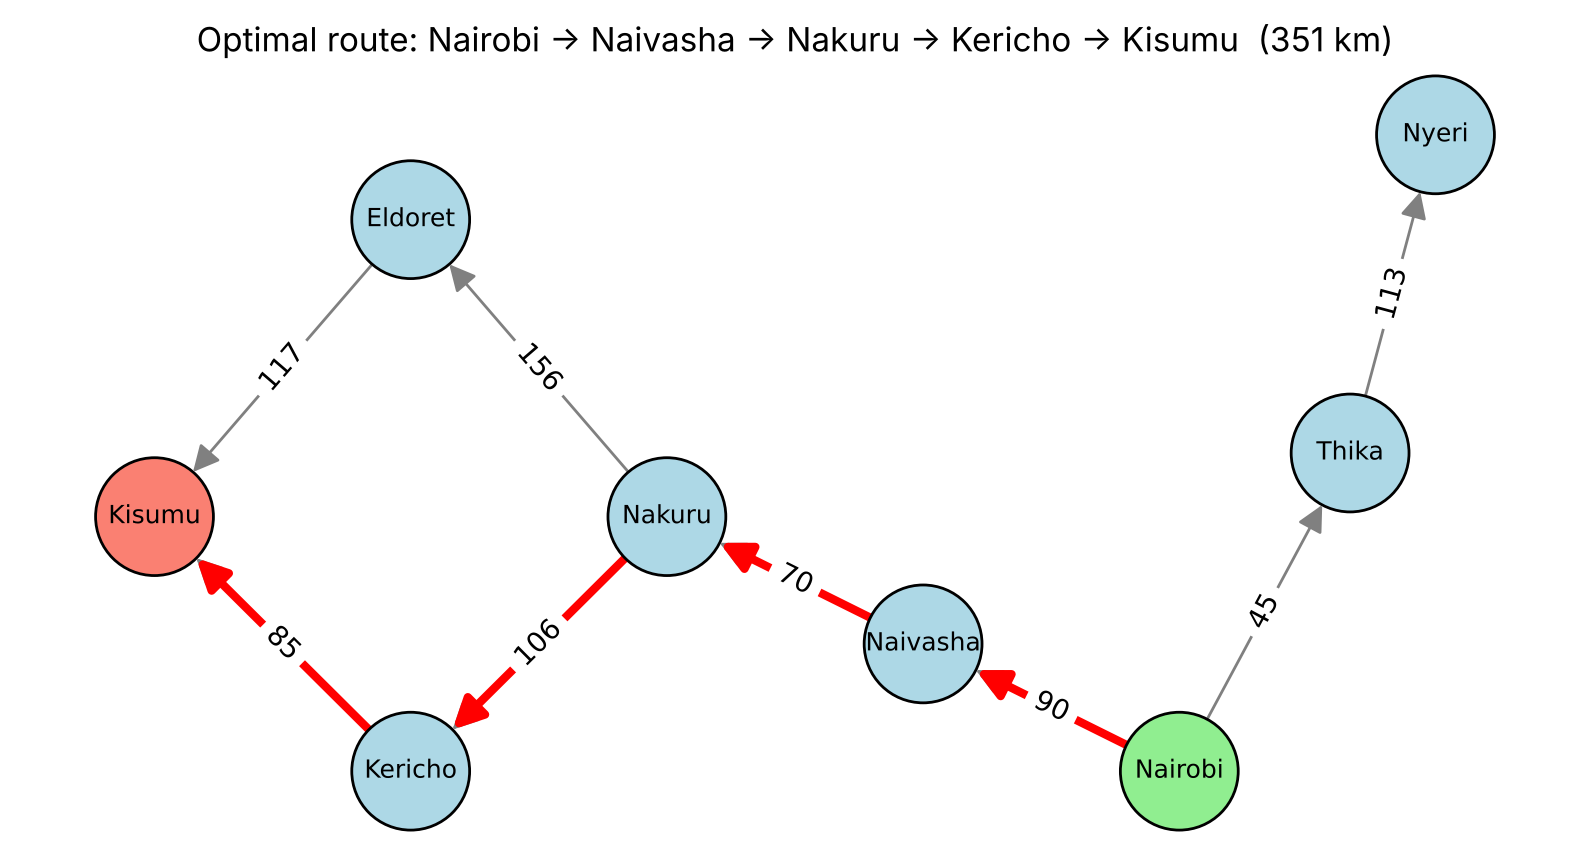

In [5]:
draw(highlight=path, title=f"Optimal route: {' -> '.join(path)}  ({total} km)")

## 5. Check: compare every possible route

In [6]:
for p in nx.all_simple_paths(G, "Nairobi", "Kisumu"):
    c = nx.path_weight(G, p, weight="weight")
    mark = "  <-- UCS answer" if p == path else ""
    print(f"{' -> '.join(p):<50} {c} km{mark}")

Nairobi -> Naivasha -> Nakuru -> Kericho -> Kisumu 351 km  <-- UCS answer
Nairobi -> Naivasha -> Nakuru -> Eldoret -> Kisumu 433 km


## 6. Conclusion
The trailer's optimal route is **Nairobi → Naivasha → Nakuru → Kericho → Kisumu**, costing **351 km** (90 + 70 + 106 + 85). The only other route, through Eldoret, costs 433 km.

Points to note from the trace:
- UCS expanded **Thika** and **Nyeri** because they were cheap at the time, even though Nyeri leads nowhere. UCS has no sense of direction; it only follows the lowest cost so far.
- Kisumu was **generated** at step 6 (cost 351) but only **accepted** at step 8, after Eldoret (316) had been expanded. Testing for the goal on expansion is what makes the result optimal.
- When Eldoret was expanded, the path to Kisumu through it (433) cost more than the one already on the frontier (351), so it was discarded.

## 7. Group work evidence
*(Replace with your team photo or link to the minutes PDF in this repo.)*

| Name | Admission No. | Role |
|---|---|---|
| | | |
| | | |

<!-- Google Drive image: share as "Anyone with the link", copy the FILE_ID, then: -->
<!-- ![Team photo](https://drive.google.com/uc?export=view&id=FILE_ID) -->